# The Arakawa C-Grid and Boundary Conditions

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/cgrid_and_boundaries.ipynb)

*Fused from somax's `arakawa_cgrid` and `boundary_conditions` tutorials.*

Every grid-based sesmax model discretises its fields on a staggered Arakawa C-grid and fills a ring of ghost cells with its boundary conditions, both supplied by [finitevolX](https://github.com/jejjohnson/finitevolX). The tutorials link here rather than repeat this.

**What you'll learn:**

1. Why the fields are staggered, and the four positions (T, U, V, X) they sit at
2. How the interior is framed by a one-cell ghost ring
3. How each boundary condition is a rule for filling those ghosts

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## Why stagger?

Consider the rotating shallow-water system, the prototype for the ocean models {cite}`vallis2017atmospheric`. Mass conservation couples the layer thickness $h$ to the divergence of the transport,

$$\frac{\partial h}{\partial t} + \nabla \cdot (h \mathbf{u}) = 0$$ (cgrid-continuity)

while the momentum balance couples the velocity $\mathbf{u} = (u, v)$ to the pressure gradient,

$$\frac{\partial \mathbf{u}}{\partial t} + f \hat{\mathbf{z}} \times \mathbf{u} = -g \nabla h$$ (cgrid-momentum)

On a collocated grid, with all variables at the cell centre, the pressure gradient in {eq}`cgrid-momentum` needs a centred two-cell stencil, which cannot see the $2 \Delta x$ checkerboard mode, so pressure and velocity decouple and spurious grid-scale noise grows. The C-grid's cure is to place $u$ and $v$ on the cell faces, half a cell from the pressure point, so the gradient in {eq}`cgrid-momentum` and the divergence in {eq}`cgrid-continuity` are compact one-cell differences {cite}`arakawa1977computational`.

### Symbols

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $(x, y)$ | spatial coordinates | $\mathbb{R}^2$ |
| $h(x, y, t)$ | layer thickness, or any scalar at T-points | $\mathbb{R}$ |
| $\mathbf{u} = (u, v)$ | velocity | $\mathbb{R}^2$ |
| $f$, $g$ | Coriolis parameter and gravity | $\mathbb{R}$, $\mathbb{R}_{>0}$ |
| $\Delta x$, $\Delta y$, $\Delta n$ | grid spacings, and the spacing normal to a boundary | $\mathbb{R}_{>0}$ |
| $i$, $j$ | column and row index | index |
| $N_{\Omega_x,x}$, $N_{\Omega_x,y}$ | number of interior cells along $x$ and $y$ | count |
| $\phi_\text{int}$, $\phi_\text{ghost}$, $\phi_\text{opposite}$ | the first interior value next to a boundary, the ghost value beyond it, and the interior value on the opposite edge | $\mathbb{R}$ |
| $c$, $\gamma$ | a boundary's prescribed value and normal gradient | $\mathbb{R}$ |

In [2]:
import finitevolx as fvx
import jax.numpy as jnp
import matplotlib.pyplot as plt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## The four positions

A 2D C-grid cell carries its variables at four locations. The index $[j, i]$ labels the south-west corner of the stencil neighbourhood, the "same-index" rule, so a U-point at $[j, i]$ lies half a cell east of the T-point at $[j, i]$.

| Position | Name | Location of $[j, i]$ | Typical field |
| --- | --- | --- | --- |
| `T` | cell centre | $(i \Delta x, j \Delta y)$ | thickness $h$, pressure |
| `U` | east face | $((i + \frac{1}{2}) \Delta x, j \Delta y)$ | $x$-velocity $u$ |
| `V` | north face | $(i \Delta x, (j + \frac{1}{2}) \Delta y)$ | $y$-velocity $v$ |
| `X` | north-east corner | $((i + \frac{1}{2}) \Delta x, (j + \frac{1}{2}) \Delta y)$ | vorticity, potential vorticity |

The placement is what the equations want: $u$ sits where $\partial h / \partial x$ is naturally defined, between two T-points, and the vorticity $\partial v / \partial x - \partial u / \partial y$ lands at the corner where the circulation around a cell is measured.

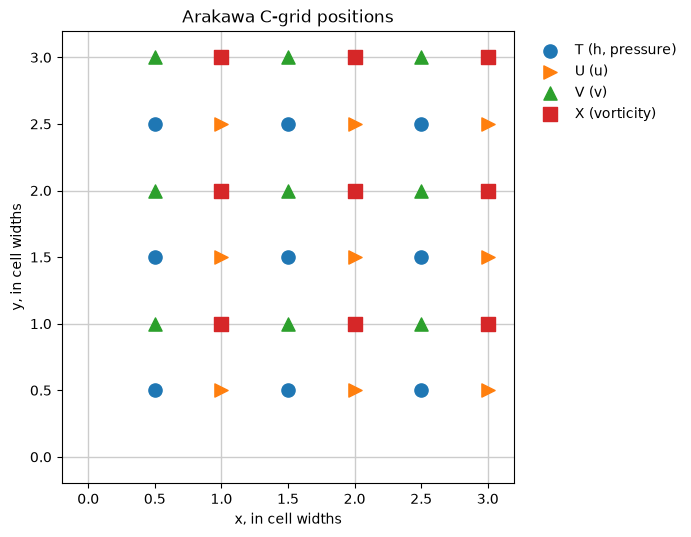

In [4]:
#| label: fig-cgrid-positions
#| caption: The four positions over a 3 × 3 block of cells.
fig, ax = plt.subplots(figsize=(7, 7))
for line in range(4):
    ax.axhline(line, color="0.8", lw=1)
    ax.axvline(line, color="0.8", lw=1)

# One marker per cell of a 3 × 3 block, offset from the cell's south-west corner
positions = [
    (0.5, 0.5, "o", "T (h, pressure)", "C0"),
    (1.0, 0.5, ">", "U (u)", "C1"),
    (0.5, 1.0, "^", "V (v)", "C2"),
    (1.0, 1.0, "s", "X (vorticity)", "C3"),
]
columns, rows = jnp.meshgrid(jnp.arange(3.0), jnp.arange(3.0))
for offset_x, offset_y, marker, label, colour in positions:
    ax.scatter(
        columns + offset_x,
        rows + offset_y,
        marker=marker,
        s=90,
        color=colour,
        label=label,
        zorder=3,
    )
ax.set_xlim(-0.2, 3.2)
ax.set_ylim(-0.2, 3.2)
ax.set_xlabel("x, in cell widths")
ax.set_ylabel("y, in cell widths")
ax.set_title("Arakawa C-grid positions")
ax.set_aspect("equal")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
plt.tight_layout()
plt.show()

Scalars (T) sit at the cell centres, velocities (U, V) on the east and north faces, and vorticity (X) at the north-east corners.

## Ghost cells frame the interior

`CartesianGrid2D.from_interior` takes the number of interior cells and the domain size, computes the spacing and adds a one-cell ghost ring. The stored arrays have $N_{\Omega_x,y} + 2$ rows and $N_{\Omega_x,x} + 2$ columns whatever their position, and every diagnostic and conserved integral is taken over the interior slice `[1:-1, 1:-1]`. In 1D the same holds with one ghost at each end.

| Array axis | `0` | `1` … `N` | `N + 1` (or `-1`) |
| --- | --- | --- | --- |
| Rows, `N` = $N_{\Omega_x,y}$ | south ghost row | interior rows | north ghost row |
| Columns, `N` = $N_{\Omega_x,x}$ | west ghost column | interior columns | east ghost column |

In [5]:
# Shapes: N_Ωx,x = N_Ωx,y = 16 interior cells;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

num_cells = 16
# today (finitevolx)
grid = fvx.CartesianGrid2D.from_interior(num_cells, num_cells, 1.0, 1.0)
interior = (slice(1, -1), slice(1, -1))
zero_field = jnp.zeros((grid.Ny, grid.Nx))  # → G

print(f"Interior cells: {num_cells} x {num_cells}")
print(f"Stored shape:   {zero_field.shape}")
print(f"Interior shape: {zero_field[interior].shape}")
print(f"Spacing:        dx = {grid.dx:.4f}, dy = {grid.dy:.4f}")

Interior cells: 16 x 16
Stored shape:   (18, 18)
Interior shape: (16, 16)
Spacing:        dx = 0.0625, dy = 0.0625


## A boundary condition is a rule for the ghosts

A stencil at the first interior cell reads a ghost value, so choosing that value is choosing the boundary condition, and no special edge stencil is needed. finitevolX implements each type as a 1D boundary object:

| Type | finitevolX class | Ghost-fill rule | Physical meaning |
| --- | --- | --- | --- |
| Periodic | `Periodic1D` | the opposite interior value | the domain wraps |
| Dirichlet | `Dirichlet1D` | $\phi_\text{ghost} = 2 c - \phi_\text{int}$ | fixed value $c$ at the face, such as a no-slip wall |
| Neumann | `Neumann1D` | $\phi_\text{ghost} = \phi_\text{int} + \gamma \Delta n$ | fixed outward normal gradient $\gamma$, such as zero flux |
| Reflective | `Reflective1D` | $\phi_\text{ghost} = \phi_\text{int}$ | mirror symmetry |
| Outflow | `Outflow1D` | $\phi_\text{ghost} = \phi_\text{int}$ | zero-gradient open boundary |

Two rules do most of the work. A periodic boundary fills each ghost from the far side of the domain,

$$\phi_\text{ghost} = \phi_\text{opposite}$$ (cgrid-periodic)

where $\phi_\text{opposite}$ is the interior value on the opposite edge, so what leaves one side re-enters from the other. A Dirichlet boundary fills it so that the average of the ghost and interior cells equals $c$,

$$\phi_\text{ghost} = 2 c - \phi_\text{int}$$ (cgrid-dirichlet)

so the value interpolated to the boundary face is the prescribed one. The check below applies each rule to the south face and prints the ghost beside the interior value.

In [6]:
# Shapes: G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

# φ(j, i) = 1 + j, so the first interior row holds 2
ramp_rows = jnp.arange(grid.Ny, dtype=jnp.float32) + 1.0  # → (N_Ωx,y + 2,)
_, ramp = jnp.meshgrid(jnp.arange(grid.Nx), ramp_rows)  # → G
checks = {
    "Periodic": fvx.Periodic1D("south"),
    "Dirichlet, c = 5": fvx.Dirichlet1D("south", value=5.0),
    "Neumann, gamma = 8": fvx.Neumann1D("south", value=8.0),
    "Reflective": fvx.Reflective1D("south"),
    "Outflow": fvx.Outflow1D("south"),
}
for name, boundary in checks.items():
    # today (finitevolx)
    filled = fvx.BoundaryConditionSet(south=boundary)(ramp, dx=grid.dx, dy=grid.dy)
    ghost = float(filled[0, 5])
    first_interior = float(filled[1, 5])
    print(f"{name:20s} ghost = {ghost:7.3f}, first interior = {first_interior:.1f}")

Periodic             ghost =  17.000, first interior = 2.0
Dirichlet, c = 5     ghost =   8.000, first interior = 2.0
Neumann, gamma = 8   ghost =   2.500, first interior = 2.0
Reflective           ghost =   2.000, first interior = 2.0
Outflow              ghost =   2.000, first interior = 2.0


## Periodic domains and channels

Most sesmax models run on a doubly periodic box and call `enforce_periodic`, which copies each interior edge into the opposite ghost ring. `BoundaryConditionSet` assigns an independent condition to each of the four faces, so a zonal channel is periodic east–west and walled north–south.

In [7]:
# Shapes: G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

# xᵢ = i Δx
x_position = jnp.arange(grid.Nx) * grid.dx  # → (N_Ωx,x + 2,)
# yⱼ = j Δy
y_position = jnp.arange(grid.Ny) * grid.dy  # → (N_Ωx,y + 2,)
x_grid, y_grid = jnp.meshgrid(x_position, y_position)  # → G each
# φ = sin(3πx) sin(2πy), with the ghosts left at zero
pattern = jnp.sin(3.0 * jnp.pi * x_grid) * jnp.sin(2.0 * jnp.pi * y_grid)  # → G
field = jnp.zeros_like(pattern).at[interior].set(pattern[interior])  # → G

# today (finitevolx)
periodic_field = fvx.enforce_periodic(field)  # → G
# today (finitevolx)
channel = fvx.BoundaryConditionSet(
    west=fvx.Periodic1D("west"),
    east=fvx.Periodic1D("east"),
    south=fvx.Dirichlet1D("south", value=0.0),
    north=fvx.Dirichlet1D("north", value=0.0),
)
channel_field = channel(field, dx=grid.dx, dy=grid.dy)  # → G

# φ₀,ᵢ against φ_N,ᵢ, the south ghost row and the north interior row
wraps = jnp.allclose(periodic_field[0, 1:-1], periodic_field[-2, 1:-1])
# φ_j,0 against φ_j,N, the west ghost column and the east interior column
channel_wraps = jnp.allclose(channel_field[1:-1, 0], channel_field[1:-1, -2])
# ½ (φ₀,ᵢ + φ₁,ᵢ) on the south wall
south_face = 0.5 * (channel_field[0, 1:-1] + channel_field[1, 1:-1])
print(f"Periodic: south ghost row = north interior row: {bool(wraps)}")
print(f"Channel: west ghost column = east interior column: {bool(channel_wraps)}")
largest_wall_value = float(jnp.abs(south_face).max())
print(f"Channel: largest |value at the south wall|: {largest_wall_value:.1e}")

Periodic: south ghost row = north interior row: True
Channel: west ghost column = east interior column: True
Channel: largest |value at the south wall|: 0.0e+00


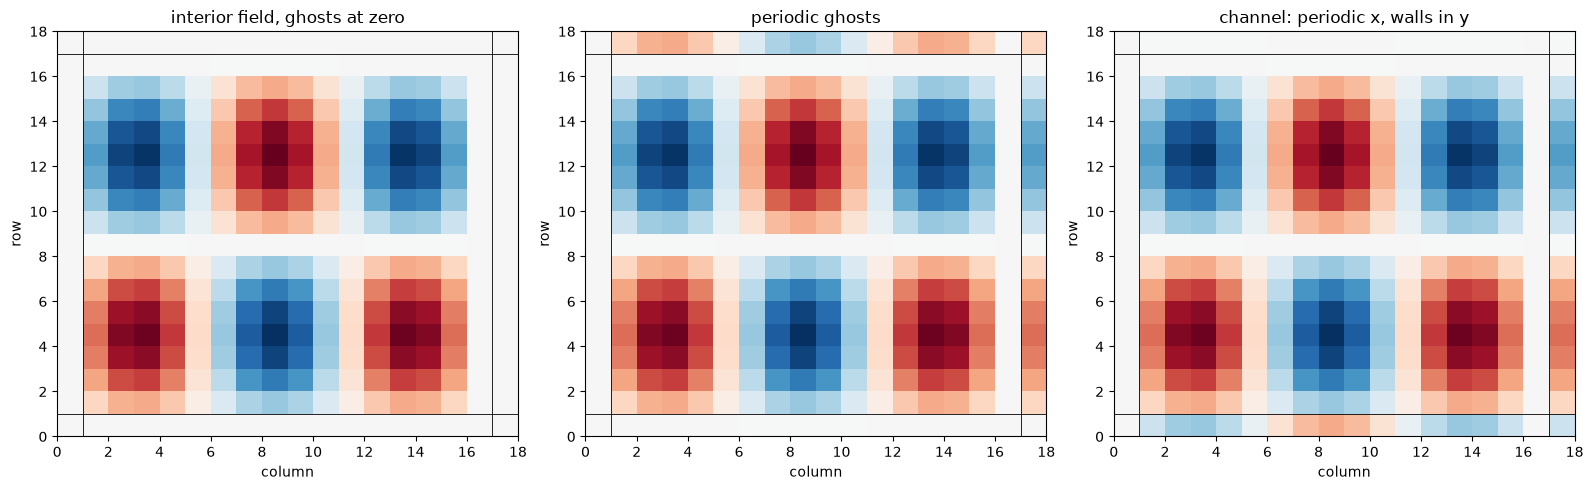

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
largest = float(jnp.abs(field).max())
panels = [
    (field, "interior field, ghosts at zero"),
    (periodic_field, "periodic ghosts"),
    (channel_field, "channel: periodic x, walls in y"),
]
for ax, (panel, title) in zip(axes, panels, strict=True):
    ax.pcolormesh(panel, cmap="RdBu_r", vmin=-largest, vmax=largest)
    ax.axhline(1, color="k", lw=0.6)
    ax.axhline(grid.Ny - 1, color="k", lw=0.6)
    ax.axvline(1, color="k", lw=0.6)
    ax.axvline(grid.Nx - 1, color="k", lw=0.6)
    ax.set_xlabel("column")
    ax.set_ylabel("row")
    ax.set_title(title)
plt.tight_layout()
plt.show()

The thin black frame marks the boundary between the interior and the ghost ring. Periodic ghosts carry the opposite edge; in the channel the north and south ghosts are the wall reflection while east and west still wrap.

## How the models use them

Each model implements `apply_boundary_conditions(state)`, and the time integrator calls it before every evaluation of the right-hand side, so the stencils always read consistent ghosts {cite}`leveque2002finite,durran2010numerical`. The boundary type is part of the model's physical specification.

Anything a stencil writes needs the same care: finitevolX's interpolations and advection write only the interior, so a periodic model fills the ghosts of its interpolated face velocities too and passes `wall="open"` to the advection operator.

## Summary

| Concept | finitevolX API |
| --- | --- |
| Build a grid | `CartesianGrid2D.from_interior(nx, ny, Lx, Ly)` |
| Interior slice | `field[1:-1, 1:-1]` |
| Doubly periodic ghosts | `enforce_periodic(field)` |
| Per-face conditions | `BoundaryConditionSet(west=..., east=..., south=..., north=...)` |

**Next:** [Steps to Navier–Stokes](../guide/steps_to_navier_stokes.md) puts the grid to work.